## 1. Understanding Class Imbalance

The dataset contains approximately 96.5% legitimate
transactions and 3.5% fraudulent transactions.

A model that predicts every transaction as legitimate
could achieve high accuracy while detecting no fraud.

Therefore, we need metrics such as Precision, Recall,
F1-score and PR-AUC to evaluate our models.

In [1]:
import pandas as pd

columns = [
    "TransactionDT", "isFraud",
    "dist2", "D7", "D13",
    "ProductCD", "card4", "card6"
]

transactions = pd.read_csv(
    "data/raw/train_transaction.csv",
    usecols=columns
)

In [2]:
transactions.shape

(590540, 8)

In [3]:
transactions["isFraud"].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

In [4]:
from sklearn.dummy import DummyClassifier

X = transactions.drop(columns=["isFraud"])
y = transactions["isFraud"]

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X, y)

predictions = baseline.predict(X)

In [5]:
from sklearn.metrics import accuracy_score

accuracy_score(y, predictions)

0.9650099908558268

In [6]:
from sklearn.metrics import recall_score

recall_score(y, predictions)

0.0

## 2. Dummy Baseline Model

We trained a DummyClassifier using the most_frequent strategy.

Results:
- Accuracy: 96.50%
- Fraud Recall: 0.00%

The model predicts every transaction as legitimate.
Despite achieving high accuracy, it fails to detect any
fraudulent transactions.

This demonstrates why accuracy is insufficient for
evaluating imbalanced fraud detection datasets.

In [7]:
cutoff = transactions["TransactionDT"].quantile(0.80)

train_mask = transactions["TransactionDT"] <= cutoff
valid_mask = transactions["TransactionDT"] > cutoff

X = transactions.drop(columns=["isFraud", "TransactionDT"])
y = transactions["isFraud"]

X_train = X.loc[train_mask]
X_valid = X.loc[valid_mask]

y_train = y.loc[train_mask]
y_valid = y.loc[valid_mask]

In [8]:
print("Training:", X_train.shape)
print("Validation:", X_valid.shape)

Training: (472432, 6)
Validation: (118108, 6)


In [9]:
print("Last training time:",
      transactions.loc[train_mask, "TransactionDT"].max())

print("First validation time:",
      transactions.loc[valid_mask, "TransactionDT"].min())

Last training time: 12192842
First validation time: 12192900


In [10]:
print("Training fraud rate:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation fraud rate:")
print(y_valid.value_counts(normalize=True) * 100)

Training fraud rate:
isFraud
0    96.486478
1     3.513522
Name: proportion, dtype: float64

Validation fraud rate:
isFraud
0    96.559082
1     3.440918
Name: proportion, dtype: float64


In [11]:
numeric_columns = ["dist2", "D7", "D13"]

medians = X_train[numeric_columns].median()

X_train[numeric_columns] = X_train[numeric_columns].fillna(medians)

X_valid[numeric_columns] = X_valid[numeric_columns].fillna(medians)

In [12]:
print(X_train[numeric_columns].isnull().sum())
print(X_valid[numeric_columns].isnull().sum())

dist2    0
D7       0
D13      0
dtype: int64
dist2    0
D7       0
D13      0
dtype: int64


In [13]:
categorical_columns = ["ProductCD", "card4", "card6"]

print(X_train[categorical_columns].isnull().sum())

ProductCD      0
card4        833
card6        828
dtype: int64


In [14]:
for col in categorical_columns:
    X_train[col] = X_train[col].fillna("Unknown")
    X_valid[col] = X_valid[col].fillna("Unknown")

In [15]:
print(X_train[categorical_columns].isnull().sum())
print(X_valid[categorical_columns].isnull().sum())

ProductCD    0
card4        0
card6        0
dtype: int64
ProductCD    0
card4        0
card6        0
dtype: int64


In [16]:
from sklearn.preprocessing import OneHotEncoder

In [17]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train[categorical_columns])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

In [18]:
X_train_encoded = encoder.transform(X_train[categorical_columns])
X_valid_encoded = encoder.transform(X_valid[categorical_columns])

In [19]:
print("Training:", X_train_encoded.shape)
print("Validation:", X_valid_encoded.shape)

Training: (472432, 15)
Validation: (118108, 15)


In [20]:
import pandas as pd

X_train_numeric = X_train[numeric_columns].reset_index(drop=True)
X_valid_numeric = X_valid[numeric_columns].reset_index(drop=True)

X_train_cat = pd.DataFrame(
    X_train_encoded,
    columns=encoder.get_feature_names_out(categorical_columns)
)

X_valid_cat = pd.DataFrame(
    X_valid_encoded,
    columns=encoder.get_feature_names_out(categorical_columns)
)

X_train_final = pd.concat(
    [X_train_numeric, X_train_cat], axis=1
)

X_valid_final = pd.concat(
    [X_valid_numeric, X_valid_cat], axis=1
)

In [21]:
print("Training:", X_train_final.shape)
print("Validation:", X_valid_final.shape)

Training: (472432, 18)
Validation: (118108, 18)


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [23]:
scaler.fit(X_train_final[numeric_columns])

StandardScaler()

In [24]:
X_train_final[numeric_columns] = scaler.transform(
    X_train_final[numeric_columns]
)

X_valid_final[numeric_columns] = scaler.transform(
    X_valid_final[numeric_columns]
)

In [25]:
print(X_train_final[numeric_columns].mean().round(2))

dist2    0.0
D7       0.0
D13      0.0
dtype: float64


In [26]:
print(X_valid_final[numeric_columns].mean().round(2))

dist2   -0.04
D7      -0.02
D13      0.02
dtype: float64


In [27]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [28]:
model.fit(X_train_final, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [29]:
y_pred = model.predict(X_valid_final)

In [30]:
import pandas as pd

pd.Series(y_pred).value_counts()

0    89686
1    28422
Name: count, dtype: int64

In [31]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.77      0.86    114044
           1       0.08      0.59      0.15      4064

    accuracy                           0.77    118108
   macro avg       0.53      0.68      0.51    118108
weighted avg       0.95      0.77      0.84    118108



In [32]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_valid, y_pred)

print(cm)

[[88015 26029]
 [ 1671  2393]]


In [33]:
from sklearn.metrics import average_precision_score

y_prob = model.predict_proba(X_valid_final)[:, 1]

pr_auc = average_precision_score(y_valid, y_prob)

print("PR-AUC:", pr_auc)

PR-AUC: 0.11268860815518297


## 3. Logistic Regression Baseline Results

Model: Logistic Regression
Class weighting: Balanced
Validation strategy: Chronological 80/20 split

Results:
- Accuracy: 77%
- Fraud Precision: 8%
- Fraud Recall: 59%
- Fraud F1-score: 15%
- Average Precision (PR-AUC): 0.1127

Confusion Matrix:
- True Negative: 88,015
- False Positive: 26,029
- False Negative: 1,671
- True Positive: 2,393

Observations:
The model detects approximately 59% of fraudulent
transactions but generates many false positives.

The results demonstrate the trade-off between
fraud detection and legitimate customer inconvenience.

Further optimization is required.

In [34]:
import numpy as np

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    recall = recall_score(y_valid, y_threshold_pred)

    print(threshold, round(recall, 3))

0.2 1.0
0.3 0.923
0.4 0.658
0.5 0.589
0.6 0.455


In [35]:
from sklearn.metrics import precision_score, recall_score

for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_valid, pred)
    recall = recall_score(y_valid, pred)

    print(
        f"Threshold: {threshold}",
        f"Precision: {precision:.3f}",
        f"Recall: {recall:.3f}"
    )

Threshold: 0.2 Precision: 0.034 Recall: 1.000
Threshold: 0.3 Precision: 0.040 Recall: 0.923


Threshold: 0.4 Precision: 0.072 Recall: 0.658
Threshold: 0.5 Precision: 0.084 Recall: 0.589
Threshold: 0.6 Precision: 0.115 Recall: 0.455


In [36]:
from sklearn.metrics import f1_score

for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_valid, pred)
    recall = recall_score(y_valid, pred)
    f1 = f1_score(y_valid, pred)

    print(
        f"Threshold: {threshold}",
        f"Precision: {precision:.3f}",
        f"Recall: {recall:.3f}",
        f"F1: {f1:.3f}"
    )

Threshold: 0.2 Precision: 0.034 Recall: 1.000 F1: 0.067


Threshold: 0.3 Precision: 0.040 Recall: 0.923 F1: 0.077
Threshold: 0.4 Precision: 0.072 Recall: 0.658 F1: 0.130
Threshold: 0.5 Precision: 0.084 Recall: 0.589 F1: 0.147
Threshold: 0.6 Precision: 0.115 Recall: 0.455 F1: 0.184


## 4. Classification Threshold Analysis

We evaluated five classification thresholds.

| Threshold | Precision | Recall | F1 |
|---|---:|---:|---:|
| 0.20 | 0.034 | 1.000 | 0.067 |
| 0.30 | 0.040 | 0.923 | 0.077 |
| 0.40 | 0.072 | 0.658 | 0.130 |
| 0.50 | 0.084 | 0.589 | 0.147 |
| 0.60 | 0.115 | 0.455 | 0.184 |

The 0.60 threshold achieved the highest F1-score
among the tested thresholds.

However, its fraud Recall was only 45.5%.

Threshold selection must consider business costs
and fraud detection requirements.

In [37]:
transactions = pd.read_csv(
    "data/raw/train_transaction.csv",
    usecols=[
        "TransactionDT", "TransactionAmt", "isFraud",
        "dist2", "D7", "D13",
        "ProductCD", "card4", "card6"
    ]
)

In [38]:
transactions["TransactionAmt"].describe()

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

In [39]:
import numpy as np

transactions["TransactionAmt_log"] = np.log1p(
    transactions["TransactionAmt"]
)

In [40]:
transactions["TransactionAmt_log"].describe()

count    590540.000000
mean          4.382960
std           0.937183
min           0.223943
25%           3.791459
50%           4.245190
75%           4.836282
max          10.371564
Name: TransactionAmt_log, dtype: float64

In [41]:
print("Original skewness:",
      transactions["TransactionAmt"].skew())

print("Log transformed skewness:",
      transactions["TransactionAmt_log"].skew())


Original skewness: 14.374489573829827
Log transformed skewness: 0.4882909971465326


## 5. Transaction Amount Feature Engineering

TransactionAmt was investigated as an additional
numeric feature.

Original skewness: 14.37
Log-transformed skewness: 0.49

Transformation:
TransactionAmt_log = log1p(TransactionAmt)

The log transformation substantially reduced
the positive skewness of the transaction amount.

The transformed feature will be evaluated in
the next Logistic Regression experiment.

In [42]:
cutoff = transactions["TransactionDT"].quantile(0.80)

train_mask = transactions["TransactionDT"] <= cutoff
valid_mask = transactions["TransactionDT"] > cutoff

y_train = transactions.loc[train_mask, "isFraud"]
y_valid = transactions.loc[valid_mask, "isFraud"]

In [43]:
numeric_columns = [
    "TransactionAmt_log",
    "dist2",
    "D7",
    "D13"
]

categorical_columns = ["ProductCD", "card4", "card6"]

X_train = transactions.loc[train_mask, numeric_columns + categorical_columns].copy()
X_valid = transactions.loc[valid_mask, numeric_columns + categorical_columns].copy()

In [44]:
print(X_train.shape)
print(X_valid.shape)

(472432, 7)
(118108, 7)


In [45]:
medians = X_train[numeric_columns].median()

X_train[numeric_columns] = X_train[numeric_columns].fillna(medians)

X_valid[numeric_columns] = X_valid[numeric_columns].fillna(medians)

In [46]:
print(X_train[numeric_columns].isnull().sum())
print(X_valid[numeric_columns].isnull().sum())

TransactionAmt_log    0
dist2                 0
D7                    0
D13                   0
dtype: int64
TransactionAmt_log    0
dist2                 0
D7                    0
D13                   0
dtype: int64


In [47]:
for col in categorical_columns:
    X_train[col] = X_train[col].fillna("Unknown")
    X_valid[col] = X_valid[col].fillna("Unknown")

In [48]:
print(X_train[categorical_columns].isnull().sum())
print(X_valid[categorical_columns].isnull().sum())

ProductCD    0
card4        0
card6        0
dtype: int64
ProductCD    0
card4        0
card6        0
dtype: int64


In [49]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train[categorical_columns])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

In [50]:
print(encoder.get_feature_names_out(categorical_columns))
print("Total encoded features:", len(encoder.get_feature_names_out(categorical_columns)))

['ProductCD_C' 'ProductCD_H' 'ProductCD_R' 'ProductCD_S' 'ProductCD_W'
 'card4_Unknown' 'card4_american express' 'card4_discover'
 'card4_mastercard' 'card4_visa' 'card6_Unknown' 'card6_charge card'
 'card6_credit' 'card6_debit' 'card6_debit or credit']
Total encoded features: 15


In [51]:
X_train_encoded = encoder.transform(
    X_train[categorical_columns]
)

X_valid_encoded = encoder.transform(
    X_valid[categorical_columns]
)

In [52]:
print("Training:", X_train_encoded.shape)
print("Validation:", X_valid_encoded.shape)

Training: (472432, 15)
Validation: (118108, 15)


In [53]:
X_train_numeric = X_train[numeric_columns].reset_index(drop=True)
X_valid_numeric = X_valid[numeric_columns].reset_index(drop=True)

X_train_cat = pd.DataFrame(
    X_train_encoded,
    columns=encoder.get_feature_names_out(categorical_columns)
)

X_valid_cat = pd.DataFrame(
    X_valid_encoded,
    columns=encoder.get_feature_names_out(categorical_columns)
)

X_train_final = pd.concat(
    [X_train_numeric, X_train_cat], axis=1
)

X_valid_final = pd.concat(
    [X_valid_numeric, X_valid_cat], axis=1
)

In [54]:
print("Training:", X_train_final.shape)
print("Validation:", X_valid_final.shape)

Training: (472432, 19)
Validation: (118108, 19)


In [55]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train_final[numeric_columns])

StandardScaler()

In [56]:
X_train_final[numeric_columns] = scaler.transform(
    X_train_final[numeric_columns]
)

X_valid_final[numeric_columns] = scaler.transform(
    X_valid_final[numeric_columns]
)

In [57]:
from sklearn.linear_model import LogisticRegression

model_v2 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_v2.fit(X_train_final, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [58]:
y_pred_v2 = model_v2.predict(X_valid_final)

In [59]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred_v2))

              precision    recall  f1-score   support

           0       0.98      0.77      0.86    114044
           1       0.09      0.61      0.15      4064

    accuracy                           0.76    118108
   macro avg       0.53      0.69      0.51    118108
weighted avg       0.95      0.76      0.84    118108



In [60]:
from sklearn.metrics import average_precision_score

y_prob_v2 = model_v2.predict_proba(X_valid_final)[:, 1]

pr_auc_v2 = average_precision_score(y_valid, y_prob_v2)

print("Experiment 2 PR-AUC:", pr_auc_v2)

Experiment 2 PR-AUC: 0.12464249542603129


In [61]:
results = pd.DataFrame({
    "Model": ["Logistic Regression V1", "Logistic Regression V2"],
    "Features": [18, 19],
    "PR_AUC": [0.1126886, pr_auc_v2],
    "Fraud_Precision": [0.08, 0.09],
    "Fraud_Recall": [0.59, 0.61],
    "Fraud_F1": [0.15, 0.15]
})

results

,Model,Features,PR_AUC,Fraud_Precision,Fraud_Recall,Fraud_F1
0,Logistic Regression V1,18,0.112689,0.08,0.59,0.15
1,Logistic Regression V2,19,0.124642,0.09,0.61,0.15


## 6. Model Experiment Comparison

Two Logistic Regression experiments were evaluated.

Experiment 1:
- Features: 18
- PR-AUC: 0.112689
- Fraud Precision: 0.08
- Fraud Recall: 0.59
- Fraud F1: 0.15

Experiment 2:
- Features: 19
- PR-AUC: 0.124642
- Fraud Precision: 0.09
- Fraud Recall: 0.61
- Fraud F1: 0.15

Experiment 2 performed better after adding
the log-transformed transaction amount feature.

The improvement suggests that transaction amount
contains useful information for fraud detection.

In [62]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

print("Legitimate weight:", weights[0])
print("Fraud weight:", weights[1])

Legitimate weight: 0.5182073259285748
Fraud weight: 14.230736791372975


In [63]:
model_none = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_custom = LogisticRegression(
    max_iter=1000,
    class_weight={0: 1, 1: 5},
    random_state=42
)

In [64]:
model_none.fit(X_train_final, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [65]:
y_pred_none = model_none.predict(X_valid_final)

In [66]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_valid, y_pred_none))
print("Recall:", recall_score(y_valid, y_pred_none))
print("F1-score:", f1_score(y_valid, y_pred_none))

Precision: 0.0
Recall: 0.0
F1-score: 0.0


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [67]:
model_custom.fit(X_train_final, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{0: 1, 1: 5}"
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm 

In [68]:
class_weight={0: 1, 1: 5}

In [69]:
y_pred_custom = model_custom.predict(X_valid_final)

In [70]:
print("Precision:", precision_score(y_valid, y_pred_custom))
print("Recall:", recall_score(y_valid, y_pred_custom))
print("F1-score:", f1_score(y_valid, y_pred_custom))

Precision: 0.24408602150537634
Recall: 0.11171259842519685
F1-score: 0.15327481431465226


In [71]:
weight_results = pd.DataFrame({
    "Model": ["Unweighted", "Balanced", "Custom 1:5"],
    "Precision": [
        precision_score(y_valid, y_pred_none),
        precision_score(y_valid, y_pred_v2),
        precision_score(y_valid, y_pred_custom)
    ],
    "Recall": [
        recall_score(y_valid, y_pred_none),
        recall_score(y_valid, y_pred_v2),
        recall_score(y_valid, y_pred_custom)
    ],
    "F1": [
        f1_score(y_valid, y_pred_none),
        f1_score(y_valid, y_pred_v2),
        f1_score(y_valid, y_pred_custom)
    ]
})

weight_results

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,Precision,Recall,F1
0,Unweighted,0.000000,0.000000,0.000000
1,Balanced,0.086095,0.608022,0.150832
2,Custom 1:5,0.244086,0.111713,0.153275


In [72]:
prob_none = model_none.predict_proba(X_valid_final)[:, 1]
prob_balanced = model_v2.predict_proba(X_valid_final)[:, 1]
prob_custom = model_custom.predict_proba(X_valid_final)[:, 1]

In [73]:
from sklearn.metrics import average_precision_score

print("Unweighted:",
      average_precision_score(y_valid, prob_none))

print("Balanced:",
      average_precision_score(y_valid, prob_balanced))

print("Custom:",
      average_precision_score(y_valid, prob_custom))

Unweighted: 0.12454259966053655
Balanced: 0.12464249542603129
Custom: 0.12606426645195368


## 7. Class Weight Experiments

Three Logistic Regression configurations were evaluated.

| Model | Precision | Recall | F1 | PR-AUC |
|---|---:|---:|---:|---:|
| Unweighted | 0.000 | 0.000 | 0.000 | 0.124543 |
| Balanced | 0.086 | 0.608 | 0.151 | 0.124642 |
| Custom 1:5 | 0.244 | 0.112 | 0.153 | 0.126064 |

Observations:
- Unweighted Logistic Regression predicted no fraud
  at the default threshold.
- Balanced weighting achieved higher fraud Recall.
- Custom 1:5 weighting achieved higher Precision.
- Custom 1:5 produced the highest PR-AUC.

Class weighting affects the Precision-Recall trade-off.
Further threshold optimization is required.

In [74]:
from imblearn.over_sampling import SMOTE
print("SMOTE imported successfully!")

SMOTE imported successfully!


In [75]:
smote = SMOTE(
    sampling_strategy="auto",
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_final,
    y_train
)

In [76]:
print(y_train_smote.value_counts())

isFraud
0    455833
1    455833
Name: count, dtype: int64


In [77]:
model_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_smote.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [78]:
y_pred_smote = model_smote.predict(X_valid_final)

In [79]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred_smote))

              precision    recall  f1-score   support

           0       0.98      0.77      0.86    114044
           1       0.09      0.61      0.15      4064

    accuracy                           0.77    118108
   macro avg       0.53      0.69      0.51    118108
weighted avg       0.95      0.77      0.84    118108



In [80]:
y_prob_smote = model_smote.predict_proba(
    X_valid_final
)[:, 1]

In [81]:
pr_auc_smote = average_precision_score(
    y_valid,
    y_prob_smote
)

print("SMOTE PR-AUC:", pr_auc_smote)

SMOTE PR-AUC: 0.12482902485725897


## 8. SMOTE Experiment

SMOTE was applied only to the training dataset.

Training class distribution after SMOTE:
- Legitimate: 455,833
- Fraud: 455,833

Validation data remained unchanged.

Results:
- Fraud Precision: 0.09
- Fraud Recall: 0.61
- Fraud F1-score: 0.15
- PR-AUC: 0.124829

Comparison:
- Balanced Logistic Regression PR-AUC: 0.124642
- Custom 1:5 Logistic Regression PR-AUC: 0.126064
- SMOTE Logistic Regression PR-AUC: 0.124829

SMOTE slightly outperformed balanced weighting
but did not outperform custom class weighting.

Custom 1:5 remains the current best experiment
based on PR-AUC.

In [82]:
import lightgbm as lgb

print(lgb.__version__)

4.7.0


In [83]:
import lightgbm as lgb

lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_train_final, y_train)

,learning_rate,0.05
,n_estimators,300
,class_weight,'balanced'
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,min_split_gain,0.0


In [84]:
from sklearn.metrics import (
    classification_report,
    average_precision_score
)

y_pred_lgb = lgb_model.predict(X_valid_final)

y_prob_lgb = lgb_model.predict_proba(X_valid_final)[:, 1]

print(classification_report(y_valid, y_pred_lgb))

ap_lgb = average_precision_score(y_valid, y_prob_lgb)

print("LightGBM Average Precision:", ap_lgb)

              precision    recall  f1-score   support

           0       0.98      0.81      0.89    114044
           1       0.10      0.59      0.17      4064

    accuracy                           0.80    118108
   macro avg       0.54      0.70      0.53    118108
weighted avg       0.95      0.80      0.86    118108

LightGBM Average Precision: 0.1588580927361667


In [85]:
results = {
    "Logistic Regression": 0.124642,
    "Custom Class Weight": 0.126064,
    "SMOTE": 0.124829,
    "LightGBM": 0.158858
}

for model_name, score in sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{model_name}: {score:.4f}")

LightGBM: 0.1589
Custom Class Weight: 0.1261
SMOTE: 0.1248
Logistic Regression: 0.1246


In [86]:
importance = pd.Series(
    lgb_model.feature_importances_,
    index=X_train_final.columns
).sort_values(ascending=False)

print(importance)

TransactionAmt_log        3932
dist2                     1753
D13                        834
D7                         577
card6_credit               330
card4_mastercard           264
ProductCD_H                227
card4_visa                 187
ProductCD_S                170
ProductCD_R                162
ProductCD_C                142
ProductCD_W                129
card6_debit                124
card4_discover              90
card4_american express      62
card4_Unknown               15
card6_Unknown                2
card6_charge card            0
card6_debit or credit        0
dtype: int32


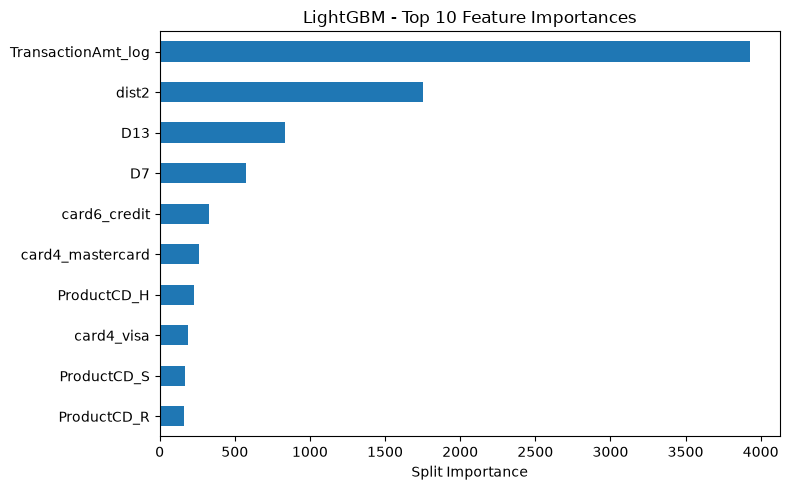

In [87]:
import matplotlib.pyplot as plt

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("LightGBM - Top 10 Feature Importances")
plt.xlabel("Split Importance")
plt.tight_layout()
plt.show()

In [88]:
import shap
print(shap.__version__)

0.54.1


In [89]:
import shap

explainer = shap.TreeExplainer(lgb_model)

X_sample = X_valid_final.sample(
    n=500,
    random_state=42
)

shap_values = explainer.shap_values(X_sample)

print("SHAP calculation completed!")

SHAP calculation completed!


/usr/local/python/3.14.2/lib/python3.14/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


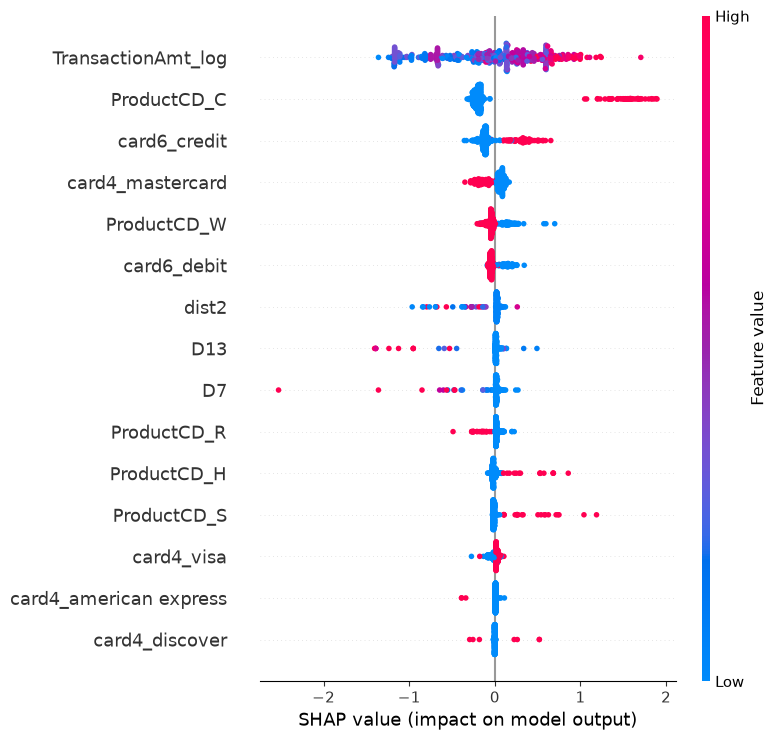

In [90]:
shap.summary_plot(
    shap_values,
    X_sample,
    max_display=15
)

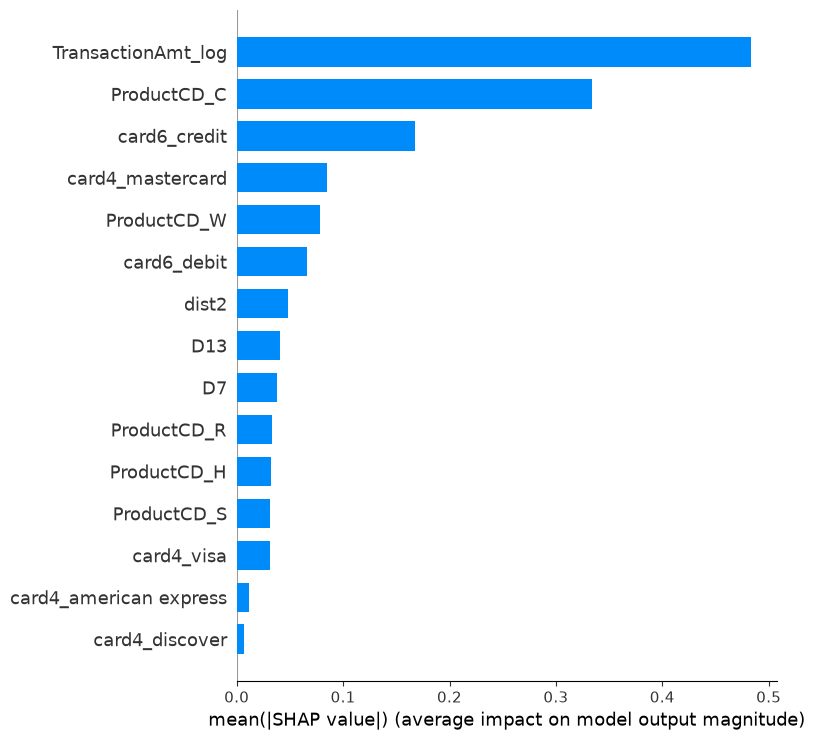

In [91]:
shap.summary_plot(
    shap_values,
    X_sample,
    plot_type="bar",
    max_display=15
)

In [92]:
lgb_model_v2 = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=50,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgb_model_v2.fit(X_train_final, y_train)

,num_leaves,50
,max_depth,10
,learning_rate,0.03
,n_estimators,500
,class_weight,'balanced'
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,subsample_for_bin,200000
,objective,None
,min_split_gain,0.0


In [93]:
from sklearn.metrics import average_precision_score, classification_report

y_pred_lgb_v2 = lgb_model_v2.predict(X_valid_final)

y_prob_lgb_v2 = lgb_model_v2.predict_proba(X_valid_final)[:, 1]

print(classification_report(y_valid, y_pred_lgb_v2))

ap_lgb_v2 = average_precision_score(
    y_valid,
    y_prob_lgb_v2
)

print("Tuned LightGBM Average Precision:", ap_lgb_v2)

              precision    recall  f1-score   support

           0       0.98      0.81      0.89    114044
           1       0.10      0.58      0.17      4064

    accuracy                           0.80    118108
   macro avg       0.54      0.70      0.53    118108
weighted avg       0.95      0.80      0.86    118108

Tuned LightGBM Average Precision: 0.1564819809862505


### LightGBM Hyperparameter Experiment

Two LightGBM configurations were evaluated using the same chronological validation set.

| Configuration | Average Precision |
|---|---:|
| Original: 300 estimators, 0.05 learning rate, 31 leaves | 0.15886 |
| Tuned: 500 estimators, 0.03 learning rate, 50 leaves, max depth 10 | 0.15648 |

**Conclusion:** The tuned configuration did not improve validation performance. The original LightGBM model remains the selected champion.

This demonstrates that increasing model complexity does not necessarily improve generalization.

In [94]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_valid, y_prob_lgb)

print("LightGBM Brier Score:", brier)

LightGBM Brier Score: 0.16432247942957795


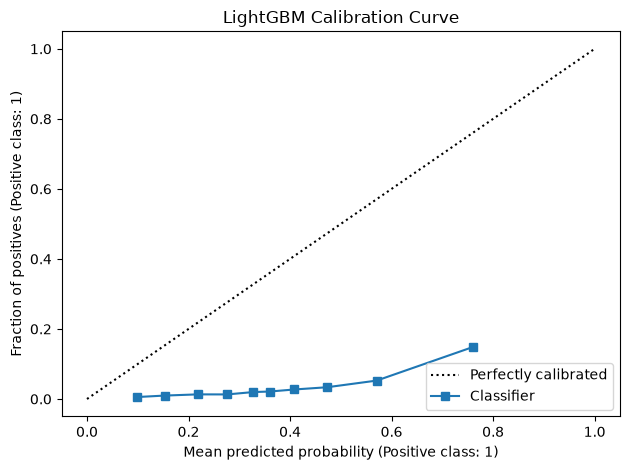

In [95]:
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

CalibrationDisplay.from_predictions(
    y_valid,
    y_prob_lgb,
    n_bins=10,
    strategy="quantile"
)

plt.title("LightGBM Calibration Curve")
plt.tight_layout()
plt.show()

In [96]:
# Sort transactions chronologically
transactions = transactions.sort_values("TransactionDT").reset_index(drop=True)

# Calculate split boundaries
train_end = int(len(transactions) * 0.70)
cal_end = int(len(transactions) * 0.85)

train_df = transactions.iloc[:train_end]
cal_df = transactions.iloc[train_end:cal_end]
test_df = transactions.iloc[cal_end:]

print("Training:", train_df.shape)
print("Calibration:", cal_df.shape)
print("Testing:", test_df.shape)

Training: (413378, 10)
Calibration: (88581, 10)
Testing: (88581, 10)


In [97]:
print("Training ends:", train_df["TransactionDT"].max())
print("Calibration starts:", cal_df["TransactionDT"].min())
print("Calibration ends:", cal_df["TransactionDT"].max())
print("Testing starts:", test_df["TransactionDT"].min())

Training ends: 10437996
Calibration starts: 10438003
Calibration ends: 13151840
Testing starts: 13151880


In [98]:
print("Training fraud rate:", train_df["isFraud"].mean())
print("Calibration fraud rate:", cal_df["isFraud"].mean())
print("Testing fraud rate:", test_df["isFraud"].mean())

Training fraud rate: 0.03516878014795175
Calibration fraud rate: 0.03434145019812375
Testing fraud rate: 0.03480430340592226


In [99]:
target = "isFraud"

X_train = train_df.drop(columns=[target, "TransactionDT"])
y_train = train_df[target]

X_cal = cal_df.drop(columns=[target, "TransactionDT"])
y_cal = cal_df[target]

X_test = test_df.drop(columns=[target, "TransactionDT"])
y_test = test_df[target]

print(X_train.shape)
print(X_cal.shape)
print(X_test.shape)

(413378, 8)
(88581, 8)
(88581, 8)


In [100]:
numeric_columns = [
    "TransactionAmt",
    "dist2",
    "D7",
    "D13"
]

categorical_columns = [
    "ProductCD",
    "card4",
    "card6"
]

print("Numerical:", numeric_columns)
print("Categorical:", categorical_columns)

Numerical: ['TransactionAmt', 'dist2', 'D7', 'D13']
Categorical: ['ProductCD', 'card4', 'card6']


In [101]:
train_medians = X_train[numeric_columns].median()

print(train_medians)

TransactionAmt    68.95
dist2             36.00
D7                 0.00
D13                0.00
dtype: float64


In [102]:
for df in [X_train, X_cal, X_test]:
    df[numeric_columns] = df[numeric_columns].fillna(train_medians)

print("Training missing:", X_train[numeric_columns].isna().sum().sum())
print("Calibration missing:", X_cal[numeric_columns].isna().sum().sum())
print("Testing missing:", X_test[numeric_columns].isna().sum().sum())

Training missing: 0
Calibration missing: 0
Testing missing: 0


In [103]:
for df in [X_train, X_cal, X_test]:
    df[categorical_columns] = (
        df[categorical_columns].fillna("Unknown")
    )

print("Training missing:", X_train[categorical_columns].isna().sum().sum())
print("Calibration missing:", X_cal[categorical_columns].isna().sum().sum())
print("Testing missing:", X_test[categorical_columns].isna().sum().sum())

Training missing: 0
Calibration missing: 0
Testing missing: 0


In [104]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train[categorical_columns])

print("Encoder fitted successfully!")
print("Encoded features:", len(encoder.get_feature_names_out()))

Encoder fitted successfully!
Encoded features: 15


In [105]:
X_train_cat = encoder.transform(X_train[categorical_columns])
X_cal_cat = encoder.transform(X_cal[categorical_columns])
X_test_cat = encoder.transform(X_test[categorical_columns])

print("Training:", X_train_cat.shape)
print("Calibration:", X_cal_cat.shape)
print("Testing:", X_test_cat.shape)

Training: (413378, 15)
Calibration: (88581, 15)
Testing: (88581, 15)


In [106]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[numeric_columns])

X_cal_num = scaler.transform(X_cal[numeric_columns])

X_test_num = scaler.transform(X_test[numeric_columns])

print("Training numerical shape:", X_train_num.shape)
print("Calibration numerical shape:", X_cal_num.shape)
print("Testing numerical shape:", X_test_num.shape)

Training numerical shape: (413378, 4)
Calibration numerical shape: (88581, 4)
Testing numerical shape: (88581, 4)


In [107]:
import numpy as np

X_train_final = np.hstack([X_train_num, X_train_cat])
X_cal_final = np.hstack([X_cal_num, X_cal_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

print("Training:", X_train_final.shape)
print("Calibration:", X_cal_final.shape)
print("Testing:", X_test_final.shape)

Training: (413378, 19)
Calibration: (88581, 19)
Testing: (88581, 19)


In [108]:
lgb_model_final = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgb_model_final.fit(X_train_final, y_train)

print("Champion LightGBM trained successfully!")

Champion LightGBM trained successfully!


In [109]:
y_cal_prob = lgb_model_final.predict_proba(X_cal_final)[:, 1]

print("Calibration probabilities generated!")
print("Minimum:", y_cal_prob.min())
print("Maximum:", y_cal_prob.max())

Calibration probabilities generated!
Minimum: 0.000469427400351923
Maximum: 0.9675769434508146


In [110]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

calibrated_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(lgb_model_final),
    method="sigmoid"
)

calibrated_model.fit(X_cal_final, y_cal)

print("Sigmoid calibration completed!")

Sigmoid calibration completed!


In [111]:
from sklearn.metrics import brier_score_loss

original_brier = brier_score_loss(
    y_cal,
    y_cal_prob
)

calibrated_prob = calibrated_model.predict_proba(
    X_cal_final
)[:, 1]

calibrated_brier = brier_score_loss(
    y_cal,
    calibrated_prob
)

print("Original Brier:", original_brier)
print("Calibrated Brier:", calibrated_brier)

Original Brier: 0.16054061648475004
Calibrated Brier: 0.031111687277764165


In [112]:
from sklearn.metrics import brier_score_loss, average_precision_score

original_test_prob = lgb_model_final.predict_proba(
    X_test_final
)[:, 1]

calibrated_test_prob = calibrated_model.predict_proba(
    X_test_final
)[:, 1]

print("Original Test Brier:",
      brier_score_loss(y_test, original_test_prob))

print("Calibrated Test Brier:",
      brier_score_loss(y_test, calibrated_test_prob))

print("Original Test AP:",
      average_precision_score(y_test, original_test_prob))

print("Calibrated Test AP:",
      average_precision_score(y_test, calibrated_test_prob))

Original Test Brier: 0.16278622549756794
Calibrated Test Brier: 0.0315007355621158
Original Test AP: 0.15171676444698942
Calibrated Test AP: 0.15171676444698942


### Probability Calibration — Sigmoid (Platt Scaling)

**Objective:** Improve the reliability of fraud probability estimates without retraining the underlying LightGBM model.

**Methodology:**
- Trained LightGBM using the chronological 70% training dataset.
- Used the next 15% as a separate calibration dataset.
- Applied sigmoid calibration using `CalibratedClassifierCV` and `FrozenEstimator`.
- Evaluated the calibrated model on the untouched final 15% test dataset.

**Final test results:**

| Metric | Original | Calibrated |
|---|---:|---:|
| Brier Score | 0.16279 | 0.03150 |
| Average Precision | 0.15172 | 0.15172 |

**Conclusion:**

Sigmoid calibration substantially improved the Brier score while preserving Average Precision. This indicates improved probability estimation without changing the ranking of fraud predictions.

The calibrated model will be retained for subsequent probability-based decision experiments.

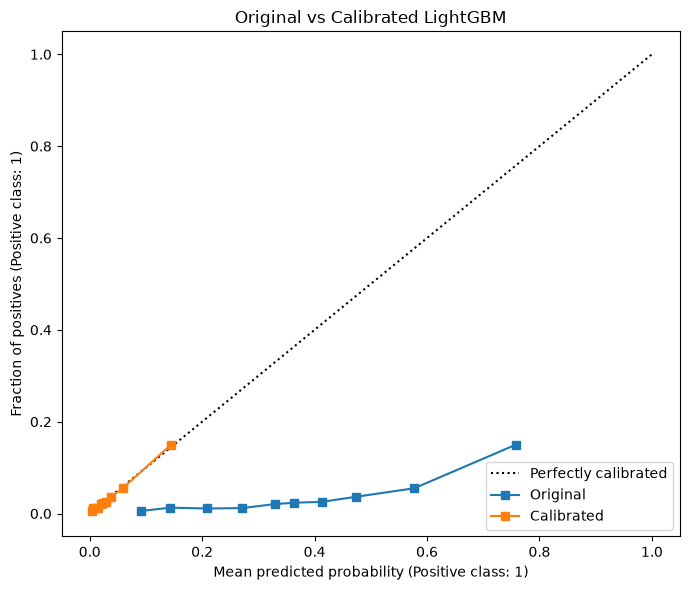

In [113]:
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))

CalibrationDisplay.from_predictions(
    y_test,
    original_test_prob,
    n_bins=10,
    strategy="quantile",
    name="Original",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_test,
    calibrated_test_prob,
    n_bins=10,
    strategy="quantile",
    name="Calibrated",
    ax=ax
)

plt.title("Original vs Calibrated LightGBM")
plt.tight_layout()
plt.show()

In [114]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30]:
    predictions = (
        calibrated_model.predict_proba(X_cal_final)[:, 1] >= threshold
    ).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_cal, predictions):.3f} | "
        f"Recall: {recall_score(y_cal, predictions):.3f}"
    )

Threshold: 0.05 | Precision: 0.109 | Recall: 0.541
Threshold: 0.10 | Precision: 0.184 | Recall: 0.343
Threshold: 0.15 | Precision: 0.216 | Recall: 0.250
Threshold: 0.20 | Precision: 0.264 | Recall: 0.111
Threshold: 0.30 | Precision: 0.348 | Recall: 0.021


### Fraud Decision Threshold Experiment

Threshold experiments were conducted using the calibration dataset and sigmoid-calibrated LightGBM probabilities.

| Threshold | Precision | Recall |
|---:|---:|---:|
| 0.05 | 0.109 | 0.541 |
| 0.10 | 0.184 | 0.343 |
| 0.15 | 0.216 | 0.250 |
| 0.20 | 0.264 | 0.111 |
| 0.30 | 0.348 | 0.021 |

**Conclusion:**

Increasing the decision threshold improves precision while reducing recall. Threshold selection must consider the operational costs of missed fraud and false alerts.

No production threshold has been selected at this stage.

In [115]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(lgb_model_final, "models/fraud_lightgbm.pkl")
joblib.dump(calibrated_model, "models/fraud_calibrated.pkl")

joblib.dump(encoder, "models/encoder.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(train_medians, "models/train_medians.pkl")

print("Model artifacts saved successfully!")

Model artifacts saved successfully!


In [116]:
import os

for file in os.listdir("models"):
    print(file, os.path.getsize(f"models/{file}"), "bytes")

fraud_lightgbm.pkl 1060836 bytes
encoder.pkl 1517 bytes
train_medians.pkl 1224 bytes
scaler.pkl 967 bytes
fraud_calibrated.pkl 1061395 bytes


In [117]:
import mlflow

mlflow.set_experiment("card-fraud-detection")

print("Experiment created successfully!")

Experiment created successfully!


In [118]:
with mlflow.start_run(run_name="lightgbm_baseline"):

    mlflow.log_params({
        "n_estimators": 300,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "class_weight": "balanced"
    })

    mlflow.log_metrics({
        "test_average_precision": 0.1517167644,
        "test_brier_score": 0.1627862255
    })

print("LightGBM experiment logged!")

LightGBM experiment logged!


In [119]:
with mlflow.start_run(run_name="lightgbm_calibrated"):

    mlflow.log_params({
        "base_model": "LightGBM",
        "calibration": "sigmoid",
        "n_estimators": 300,
        "learning_rate": 0.05
    })

    mlflow.log_metrics({
        "test_average_precision": 0.1517167644,
        "test_brier_score": 0.0315007356
    })

print("Calibrated model logged!")

Calibrated model logged!


In [120]:
with mlflow.start_run(run_name="calibrated_model_artifact"):

    mlflow.log_artifact(
        "models/fraud_calibrated.pkl",
        artifact_path="model_files"
    )

print("Calibrated model artifact logged!")

Calibrated model artifact logged!


In [121]:
from src.models.train import setup_experiment

setup_experiment()

MLflow experiment ready!


In [122]:
import mlflow
from src.models.train import (
    setup_experiment,
    log_metrics,
    log_params,
    log_model_artifact
)

setup_experiment()

with mlflow.start_run(run_name="tracking_module_test"):

    log_params({"model": "LightGBM", "n_estimators": 300})

    log_metrics({"average_precision": 0.1517})

    log_model_artifact("models/fraud_calibrated.pkl")

print("Tracking module test successful!")

MLflow experiment ready!
Tracking module test successful!


In [123]:
from src.models.train import track_experiment

track_experiment(
    run_name="complete_tracking_test",
    params={
        "model": "LightGBM",
        "n_estimators": 300,
        "learning_rate": 0.05
    },
    metrics={
        "average_precision": 0.1517,
        "brier_score": 0.0315
    },
    model_path="models/fraud_calibrated.pkl"
)

Experiment 'complete_tracking_test' logged successfully!
